# Netflix Content Trend Analysis by Release Year

---

## Project Overview

This notebook analyzes the historical distribution of Netflix content based on release years. The analysis focuses on examining yearly content releases, identifying growth and decline trends, and understanding historical patterns in the Netflix content catalog.

---

### Objectives

1. Organize Netflix content based on release year.
2. Calculate the number of Netflix titles released in each year.
3. Identify yearly growth and decline trends.
4. Visualize historical content release patterns.
5. Generate business insights based on the analysis.

### Dataset

The analysis uses the cleaned Netflix dataset generated in Notebook 01.

### Tools & Libraries

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn

### Expected Deliverables

- Yearly content release summary.
- Year-over-year growth analysis.
- Identification of content growth and decline trends.
- Historical trend visualizations.
- Key findings and business insights.

---

## Import Libraries

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Configure display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.2f}'.format)

# Set visualization style
sns.set_theme(style='whitegrid')

## Data Loading

This section loads the cleaned Netflix dataset and performs an initial inspection of its structure and release year information.

In [2]:
# Load cleaned Netflix dataset
file_path = Path("../Dataset/Cleaned_Netflix_Data.csv")
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print(f"Total Records: {df.shape[0]:,}")
print(f"Total Columns: {df.shape[1]}")

Dataset loaded successfully!
Total Records: 8,786
Total Columns: 10


### Preview Dataset

In [3]:
# Display dataset information
print(f"Dataset Shape: {df.shape}")
display(df.head())

Dataset Shape: (8786, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


## Initial Release Year Data Exploration

This section examines the release year column to understand its data structure, distribution, missing values, and historical coverage.

The findings will help determine the appropriate approach for analyzing yearly content releases and identifying historical trends.

### Release Year Data Overview

This section provides an overview of the `release_year` column, including the total number of records, missing values, unique release years, and the range of release years available in the dataset.

This overview helps assess the completeness and historical coverage of the data before proceeding with the trend analysis.

In [4]:
# Display release year data overview
release_year_overview = pd.DataFrame({
    'Metric': [
        'Total Records',
        'Missing Release Year',
        'Unique Release Years',
        'Earliest Release Year',
        'Latest Release Year'
    ],
    'Value': [
        len(df),
        df['release_year'].isna().sum(),
        df['release_year'].nunique(),
        df['release_year'].min(),
        df['release_year'].max()
    ]
})

display(release_year_overview)

,Metric,Value
0,Total Records,8786
1,Missing Release Year,0
2,Unique Release Years,74
3,Earliest Release Year,1925
4,Latest Release Year,2021


### Release Year Data Type Inspection

This section examines the data type and descriptive statistics of the `release_year` column.

The inspection helps verify whether the column is stored in an appropriate numerical format and provides an initial understanding of the distribution of release years.

In [5]:
# Inspect release year data type
print("Release Year Data Type:", df['release_year'].dtype)

# Display descriptive statistics
display(df['release_year'].describe())

Release Year Data Type: int64


count   8786.00
mean    2014.18
std        8.83
min     1925.00
25%     2013.00
50%     2017.00
75%     2019.00
max     2021.00
Name: release_year, dtype: float64

### Release Year Distribution Inspection

This section examines the number of titles associated with each release year. The analysis focuses on identifying the earliest and latest release years and observing how the number of titles is distributed across the available years.

This inspection provides an initial understanding of the historical distribution of titles before conducting yearly trend analysis.

In [6]:
# Calculate content counts by release year
release_year_counts = (
    df['release_year']
    .value_counts()
    .sort_index()
)

# Display the earliest release years
print("Earliest Release Years:")
display(release_year_counts.head(15))

# Display the latest release years
print("Latest Release Years:")
display(release_year_counts.tail(15))

Earliest Release Years:


release_year
1925    1
1942    2
1943    3
1944    3
1945    4
1946    2
1947    1
1954    2
1955    3
1956    2
1958    3
1959    1
1960    4
1961    1
1962    3
Name: count, dtype: int64

Latest Release Years:


release_year
2007      88
2008     135
2009     152
2010     192
2011     185
2012     236
2013     286
2014     351
2015     555
2016     901
2017    1030
2018    1144
2019    1029
2020     953
2021     592
Name: count, dtype: int64

## Yearly Content Releases

This section calculates the total number of titles associated with each release year.

The yearly aggregation provides a structured summary of the content distribution over time and serves as the foundation for identifying historical growth and decline patterns.

In [7]:
# Calculate yearly content releases
yearly_releases = (
    df.groupby('release_year')
    .size()
    .reset_index(name='total_titles')
    .sort_values('release_year')
)

# Display yearly content releases
display(yearly_releases)

,release_year,total_titles
0,1925,1
1,1942,2
2,1943,3
3,1944,3
4,1945,4
5,1946,2
6,1947,1
7,1954,2
8,1955,3
9,1956,2


## Year-over-Year (YoY) Growth Analysis

This section measures the annual changes in the number of titles compared to the previous year.

The analysis calculates both the absolute difference and percentage growth to identify periods of significant increases and decreases in the yearly distribution of Netflix titles.

In [8]:
# Create a complete yearly index
all_years = range(
    df['release_year'].min(),
    df['release_year'].max() + 1
)

# Recalculate yearly content releases
yearly_releases = (
    df.groupby('release_year')
    .size()
    .reindex(all_years, fill_value=0)
    .rename_axis('release_year')
    .reset_index(name='total_titles')
)

# Calculate year-over-year changes
yearly_releases['title_change'] = (
    yearly_releases['total_titles'].diff()
)

yearly_releases['growth_rate'] = (
    yearly_releases['total_titles'].pct_change() * 100
)

# Display yearly growth analysis
display(yearly_releases)

,release_year,total_titles,title_change,growth_rate
0,1925,1,NaN,NaN
1,1926,0,-1.00,-100.00
2,1927,0,0.00,NaN
3,1928,0,0.00,NaN
4,1929,0,0.00,NaN
5,1930,0,0.00,NaN
6,1931,0,0.00,NaN
7,1932,0,0.00,NaN
8,1933,0,0.00,NaN
9,1934,0,0.00,NaN


## Yearly Content Release Trend

This section visualizes the yearly distribution of Netflix titles using a line chart.

The visualization helps identify long-term patterns, periods of significant growth, peak release years, and potential declines in the number of titles across the observed period.

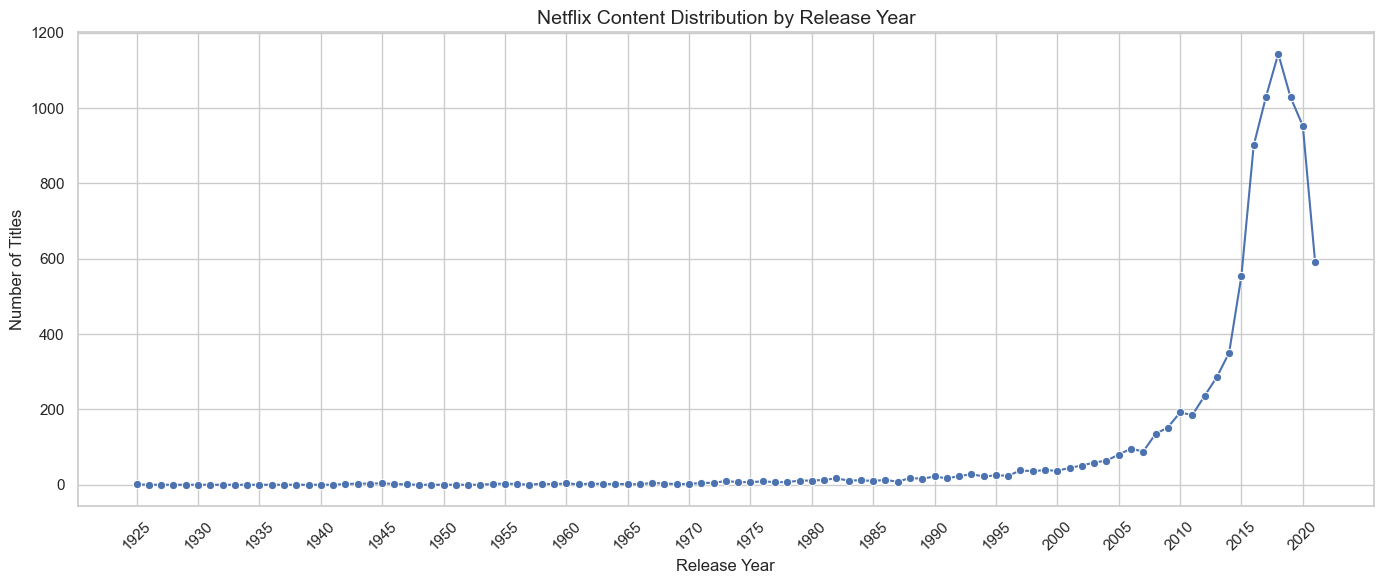

In [9]:
# Visualize yearly content release trends
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=yearly_releases,
    x='release_year',
    y='total_titles',
    marker='o'
)

plt.title('Netflix Content Distribution by Release Year', fontsize=14)
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.xticks(
    range(
        yearly_releases['release_year'].min(),
        yearly_releases['release_year'].max() + 1,
        5
    ),
    rotation=45
)

plt.tight_layout()
plt.show()

## Focused Release Year Trend (2000–2021)

This section provides a closer examination of the yearly content distribution from 2000 to 2021.

By narrowing the analysis period, the visualization highlights changes in the number of titles during more recent years, making growth patterns and declines easier to observe.

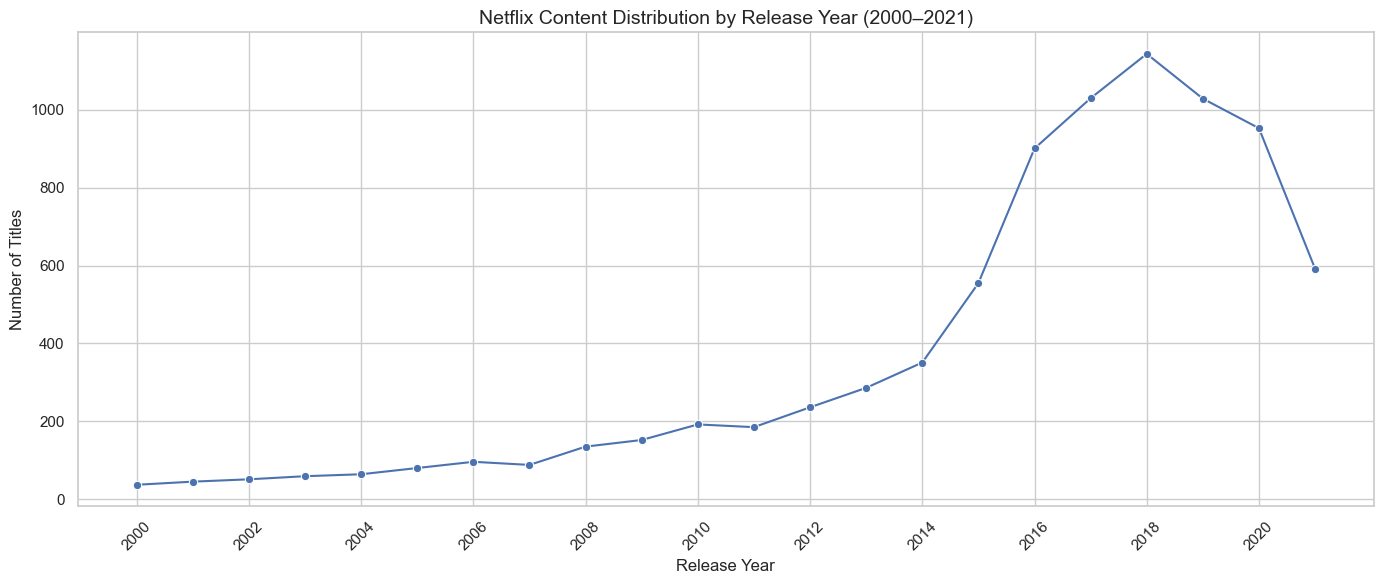

In [10]:
# Filter yearly releases from 2000 onwards
recent_yearly_releases = yearly_releases[
    yearly_releases['release_year'] >= 2000
].copy()

# Visualize focused yearly content trends
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=recent_yearly_releases,
    x='release_year',
    y='total_titles',
    marker='o'
)

plt.title('Netflix Content Distribution by Release Year (2000–2021)', fontsize=14)
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.xticks(
    range(2000, 2022, 2),
    rotation=45
)

plt.tight_layout()
plt.show()

## Key Findings and Business Insights


### Key Findings

The release-year trend analysis reveals several patterns in the historical distribution of Netflix titles.

The analysis reveals the following findings:

1. **Historical Content Distribution:** The dataset contains titles released between 1925 and 2021. However, the number of titles from earlier decades is relatively low compared to more recent years.

2. **Significant Growth in Recent Years:** The number of titles increased substantially between 2015 and 2018. The yearly distribution reached its highest point in 2018, with 1,144 titles.

3. **Peak Release Year:** 2018 recorded the highest number of titles in the dataset, followed by 2019 with 1,029 titles and 2020 with 953 titles.

4. **Declining Trend After 2018:** The number of titles declined from 1,144 in 2018 to 592 in 2021. The largest annual decrease occurred between 2020 and 2021, with 361 fewer titles, representing a decline of approximately 37.88%.

### Business Insights

The release-year distribution indicates that the Netflix catalog in this dataset is heavily represented by titles released in more recent years, particularly between 2015 and 2020. The substantial increase leading up to 2018 highlights a period with a high concentration of titles in the catalog, while the subsequent decline reflects a change in the distribution of recorded titles.

Monitoring these historical patterns can provide a useful overview of catalog composition and help identify changes in the representation of titles across different release periods. Further information, such as content availability dates, licensing status, and audience engagement metrics, would be needed to understand the underlying factors and evaluate actual content performance.

### Analysis Limitations

This analysis is based on title metadata and release years. Therefore, the number of titles in each year represents the distribution of titles recorded in the dataset, not necessarily Netflix's actual annual production volume.

The observed increase or decline should not be interpreted as direct evidence of changes in viewership, audience preferences, revenue, or Netflix's production strategy.